# BrainScan-V2 : Partie 1, Classification des tumeurs cérébrales (GoogLeNet)

Pipeline de préparation des données : validation, doublons, exploration, split 70/15/15, augmentation, `tf.data`.
Le notebook est ré-exécutable de haut en bas (le dossier `data/split` est recréé à chaque exécution).

In [ ]:
import random
import shutil
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from PIL import Image
from sklearn.model_selection import train_test_split

IMG_SIZE = 224
IMG_EXT = ('.png', '.jpeg', '.jpg', '.bmp')
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

ROOT = Path.cwd().parent            
DATA_DIR = ROOT / 'data'
SPLIT_DIR = DATA_DIR / 'split'      

# official dataset folders 
SOURCE_NAMES = {'train', 'val'}
SOURCE_DIRS = sorted(d for d in DATA_DIR.iterdir() if d.is_dir() and d.name.lower() in SOURCE_NAMES)
assert SOURCE_DIRS, f"No Train/Val folder found in {DATA_DIR}"

print('Project root :', ROOT)
print('Source folders:', [d.name for d in SOURCE_DIRS])

Project root : c:\BrainScan_V2
Source folders: ['Train', 'Val']


## 1. Chargement et prétraitement du dataset
### 1.1 Chargement et contrôle qualité


In [25]:
def normalize_label(name):
    return name.strip().lower().replace(' ', '_')


def check_image(path):
    try:
        with Image.open(path) as im:
            im.verify()              # detects most corruption
        with Image.open(path) as im:  # verify() invalidates the file, so reopen
            im.load()                
            w, h = im.size
        return True, '', w, h
    except Exception as e:
        return False, f'corrupted: {e}', None, None


records = []
for source_dir in SOURCE_DIRS:
    for class_dir in sorted(p for p in source_dir.iterdir() if p.is_dir()):
        label = normalize_label(class_dir.name)

        images_dir = class_dir / 'images'          # this dataset: images/ and labels/
        if not images_dir.is_dir():
            images_dir = class_dir                 # fallback: images directly in the class folder

        for file in images_dir.iterdir():          # was: class_dir.iterdir()
            if not file.is_file():
                continue
            row = dict(path=str(file), label=label, source=source_dir.name)
            if file.suffix.lower() not in IMG_EXT:
                row.update(ok=False, reason='bad extension', w=None, h=None)
            else:
                ok, reason, w, h = check_image(file)
                row.update(ok=ok, reason=reason, w=w, h=h)
            records.append(row)

all_df = pd.DataFrame(records)
files_df = all_df[all_df['ok']].drop(columns=['ok', 'reason']).reset_index(drop=True)
files_df[['w', 'h']] = files_df[['w', 'h']].astype(int)
invalid_df = all_df[~all_df['ok']]

print(f"Valid images:   {len(files_df)}")
print(f"Invalid images: {len(invalid_df)}  (discarded)")
if len(invalid_df):
    display(invalid_df[['path', 'reason']])
print()
print(files_df.groupby(['source', 'label']).size().unstack())

Valid images:   5249
Invalid images: 0  (discarded)

label   glioma  meningioma  no_tumor  pituitary
source                                         
Train     1153        1449       711       1424
Val        136         140       100        136


### 1.2 Détection des doublons

In [26]:
HASH_SIZE = 16    
MAX_DIST = 6     

def dhash(path, size=HASH_SIZE):
    with Image.open(path) as im:
        g = im.convert('L').resize((size + 1, size))
    a = np.asarray(g, dtype=np.int16)
    return (a[:, 1:] > a[:, :-1]).flatten()         


df = files_df.copy()
hashes = np.stack([dhash(p) for p in df['path']]).astype(np.float32)   
inv = 1 - hashes
n = len(df)

# number of differing bits between every pair 
pairs = []
for start in range(0, n, 1000):
    stop = min(start + 1000, n)
    dist = hashes[start:stop] @ inv.T + inv[start:stop] @ hashes.T
    later = np.arange(n)[None, :] > np.arange(start, stop)[:, None]    # only count each pair once
    rows, cols = np.where((dist <= MAX_DIST) & later)
    pairs += [(start + r, c, int(dist[r, c])) for r, c in zip(rows, cols)]

pairs_df = pd.DataFrame(pairs, columns=['i', 'j', 'dist'])
labels = df['label'].values
sources = df['source'].values

# same image under two different classes = ambiguous -> drop every copy
conflict = {int(k) for i, j in zip(pairs_df['i'], pairs_df['j']) if labels[i] != labels[j] for k in (i, j)}
# otherwise keep the first image of each group, drop the later copies
copies = {int(j) for j in pairs_df['j']}
drop_idx = sorted(copies | conflict)

cross_source = sum(sources[i] != sources[j] for i, j in zip(pairs_df['i'], pairs_df['j']))
print(f"Duplicate pairs found      : {len(pairs_df)}")
print(f"  exact (0 bit difference) : {(pairs_df['dist'] == 0).sum()}")
print(f"  near-identical           : {(pairs_df['dist'] > 0).sum()}")
print(f"  across Train/Val folders : {cross_source}   <- leakage in the official split")
print(f"Same image, different label: {len(conflict)} images")
print(f"Images to drop             : {len(drop_idx)} / {n}")

Duplicate pairs found      : 2300
  exact (0 bit difference) : 1635
  near-identical           : 665
  across Train/Val folders : 360   <- leakage in the official split
Same image, different label: 0 images
Images to drop             : 1535 / 5249


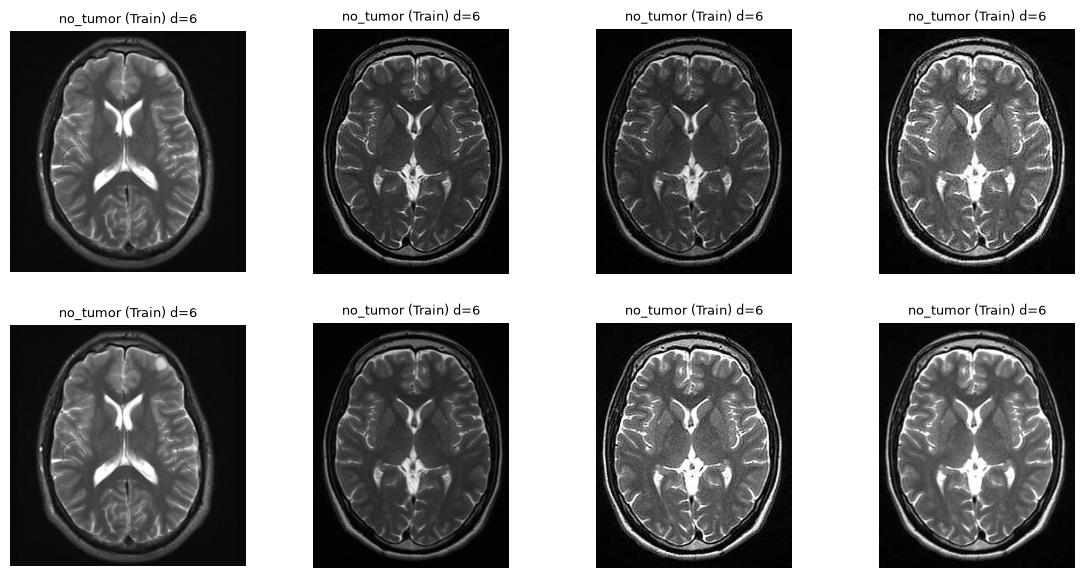

In [27]:
# visual check: the most doubtful pairs to validate MAX_DIST
if len(pairs_df):
    show = pairs_df.sort_values('dist', ascending=False).head(4)
    fig, axes = plt.subplots(2, len(show), figsize=(3.5 * len(show), 7), squeeze=False)
    for col, (_, r) in enumerate(show.iterrows()):
        for row, idx in enumerate((int(r['i']), int(r['j']))):
            axes[row, col].imshow(Image.open(df['path'][idx]), cmap='gray')
            axes[row, col].set_title(f"{df['label'][idx]} ({df['source'][idx]}) d={int(r['dist'])}", fontsize=9)
            axes[row, col].axis('off')
    plt.show()
else:
    print('No duplicates found')

In [28]:
before = len(df)
df = df.drop(index=drop_idx).reset_index(drop=True)
print(f"Images: {before} -> {len(df)}  ({before - len(df)} removed)")

Images: 5249 -> 3714  (1535 removed)


### 1.3 Exploration des classes

Classes: ['glioma', 'meningioma', 'no_tumor', 'pituitary']
label
glioma        1190
meningioma    1087
pituitary     1026
no_tumor       411
Name: count, dtype: int64


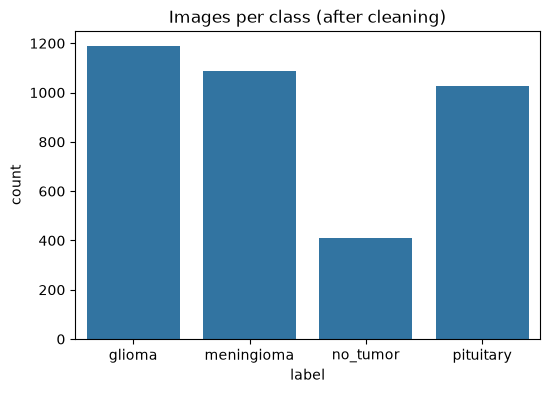

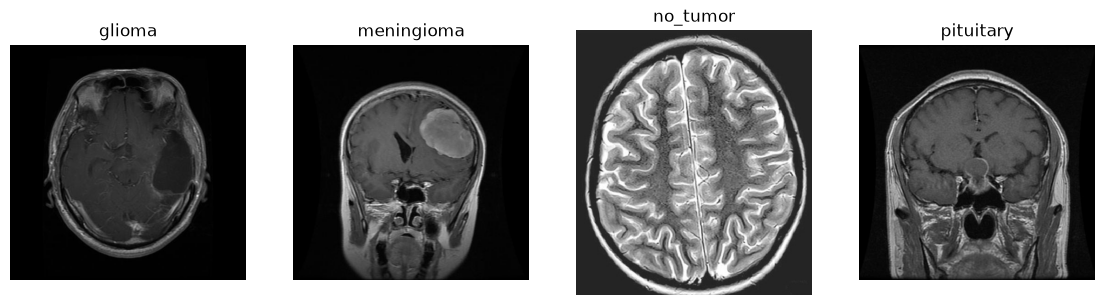

w    h  
512  512    3160
225  225      53
442  442      22
630  630      19
256  256      18
Name: count, dtype: int64


In [29]:
classes = sorted(df['label'].unique())
print('Classes:', classes)
print(df['label'].value_counts())

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='label', order=classes)
plt.title('Images per class (after cleaning)')
plt.show()

fig, axes = plt.subplots(1, len(classes), figsize=(14, 4))
for ax, cls in zip(axes, classes):
    sample_path = df[df['label'] == cls].sample(1, random_state=SEED)['path'].values[0]
    ax.imshow(Image.open(sample_path), cmap='gray')
    ax.set_title(cls)
    ax.axis('off')
plt.show()

print(df[['w', 'h']].value_counts().head())   # original sizes (we resize to 224x224 later)

### 1.4 Répartition Train / Validation / Test (70 / 15 / 15)

Le dataset officiel contient déjà Train et Val, mais pas de Test, et ses proportions ne sont pas 70/15/15.
On **fusionne** les images propres (sans doublons), puis on re-divise avec `stratify` pour garder les mêmes proportions de classes dans chaque ensemble.

Train: 2599
Valid: 557
Test : 558


,Train,Valid,Test
label,,,
glioma,833,178,179
meningioma,761,163,163
pituitary,718,154,154
no_tumor,287,62,62


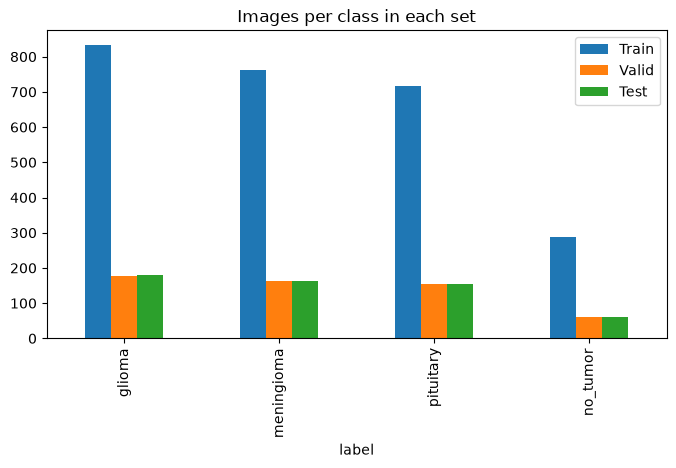

In [30]:
train_df, temp_df = train_test_split(
    df, test_size=0.3, stratify=df['label'], random_state=SEED
)
valid_df, test_df = train_test_split(
    temp_df, test_size=0.5, stratify=temp_df['label'], random_state=SEED
)

print('Train:', len(train_df))
print('Valid:', len(valid_df))
print('Test :', len(test_df))

counts = pd.DataFrame({
    'Train': train_df['label'].value_counts(),
    'Valid': valid_df['label'].value_counts(),
    'Test': test_df['label'].value_counts(),
})
display(counts)

counts.plot(kind='bar', figsize=(8, 4), title='Images per class in each set')
plt.show()

### 1.5 Copie dans `data/split/`

Le dossier est supprimé puis recréé à chaque exécution : on ne mélange jamais d'anciens fichiers avec les nouveaux.

In [31]:
assert SPLIT_DIR.name == 'split'            # safety: we only ever delete the generated folder
if SPLIT_DIR.exists():
    shutil.rmtree(SPLIT_DIR)


def copy_files(dataframe, set_name):
    for _, row in dataframe.iterrows():
        dest = SPLIT_DIR / set_name / row['label']
        dest.mkdir(parents=True, exist_ok=True)
        # source prefix avoids name clashes between the Train and Val folders
        shutil.copy(row['path'], dest / f"{row['source']}_{Path(row['path']).name}")


copy_files(train_df, 'train')
copy_files(valid_df, 'val')
copy_files(test_df, 'test')

# keep a record of which image went where (traceability)
pd.concat([train_df.assign(set='train'), valid_df.assign(set='val'), test_df.assign(set='test')]) \
  .to_csv(DATA_DIR / 'split_manifest.csv', index=False)

print('Copy done ->', SPLIT_DIR)

Copy done -> c:\BrainScan_V2\data\split


### 1.6 Augmentation des données (train uniquement)

Val et Test ne sont **jamais** augmentés : ils simulent des données réelles jamais vues.

In [ ]:
def blur(img):
    return cv2.GaussianBlur(img, (5, 5), 0)


def add_noise(img):
    noise = np.random.normal(0, 15, img.shape)
    noisy = img.astype(np.float32) + noise
    return np.clip(noisy, 0, 255).astype(np.uint8)


def flip(img):
    return cv2.flip(img, 1)

In [ ]:
sample = next((SPLIT_DIR / 'train' / 'glioma').glob('*'))
img = cv2.imread(str(sample))
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)   # OpenCV reads BGR, matplotlib expects RGB

versions = {'original': img, 'blur': blur(img), 'noise': add_noise(img), 'flip': flip(img)}

fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, (name, im) in zip(axes, versions.items()):
    ax.imshow(im)
    ax.set_title(name)
    ax.axis('off')
plt.show()

In [ ]:
random.seed(SEED)
np.random.seed(SEED)

augmentations = {'blur': blur, 'flip': flip, 'noise': add_noise}

TRAIN_DIR = SPLIT_DIR / 'train'

class_counts = {c.name: len(list(c.glob('*'))) for c in TRAIN_DIR.iterdir()}
target = max(class_counts.values())
print('Before:', class_counts, '-> target:', target)

for class_name, count in class_counts.items():
    class_dir = TRAIN_DIR / class_name
    originals = [f for f in class_dir.glob('*') if not f.name.startswith('aug_')]
    n_missing = target - count

    for i in range(n_missing):
        src = random.choice(originals)
        aug_name, aug_func = random.choice(list(augmentations.items()))

        img = cv2.imread(str(src))
        new_img = aug_func(img)

        new_path = class_dir / f'aug_{i}_{aug_name}_{src.name}'
        cv2.imwrite(str(new_path), new_img)

class_counts = {c.name: len(list(c.glob('*'))) for c in TRAIN_DIR.iterdir()}
print('After: ', class_counts)

### 1.7 Pipeline `tf.data` : chargement, batch, normalisation

In [ ]:
import tensorflow as tf

BATCH_SIZE = 32


def load_ds(folder, shuffle):
    return tf.keras.utils.image_dataset_from_directory(
        str(SPLIT_DIR / folder),
        image_size=(IMG_SIZE, IMG_SIZE),
        batch_size=BATCH_SIZE,
        label_mode='categorical',
        shuffle=shuffle,
        seed=SEED,
    )


train_ds = load_ds('train', shuffle=True)
val_ds = load_ds('val', shuffle=False)
test_ds = load_ds('test', shuffle=False)

class_names = train_ds.class_names
print(class_names)

In [ ]:
def normalize(x, y):
    return (tf.cast(x, tf.float32) / 127.5) - 1.0, y   # [0, 255] -> [-1, 1]


AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.map(normalize, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
val_ds = val_ds.map(normalize, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)
test_ds = test_ds.map(normalize, num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)

# check one batch
for images, labels in train_ds.take(1):
    print(images.shape, labels.shape)
    print('min/max:', images.numpy().min(), images.numpy().max())